DQN device: cpu

Starting SUMO simulation...
SUMO started successfully.
Step:   500/10000 | Phase: 2 | Action: 0 | Queue:   2 | Avg Queue: 1.97 | Avg Reward: -1.97 | Loss: 0.0000 | Epsilon: 1.000 | Memory: 500
Step:  1000/10000 | Phase: 0 | Action: 0 | Queue:   2 | Avg Queue: 2.74 | Avg Reward: -2.74 | Loss: 1.4935 | Epsilon: 0.779 | Memory: 1000
Step:  1500/10000 | Phase: 2 | Action: 0 | Queue:   3 | Avg Queue: 2.79 | Avg Reward: -2.79 | Loss: 1.3227 | Epsilon: 0.606 | Memory: 1500
Step:  2000/10000 | Phase: 0 | Action: 0 | Queue:   3 | Avg Queue: 2.83 | Avg Reward: -2.83 | Loss: 1.0175 | Epsilon: 0.472 | Memory: 2000
Step:  2500/10000 | Phase: 2 | Action: 0 | Queue:   3 | Avg Queue: 2.63 | Avg Reward: -2.63 | Loss: 0.7978 | Epsilon: 0.368 | Memory: 2500
Step:  3000/10000 | Phase: 0 | Action: 0 | Queue:   6 | Avg Queue: 3.13 | Avg Reward: -3.13 | Loss: 0.7617 | Epsilon: 0.286 | Memory: 3000
Step:  3500/10000 | Phase: 2 | Action: 0 | Queue:   3 | Avg Queue: 2.96 | Avg Reward: -2.96 | L

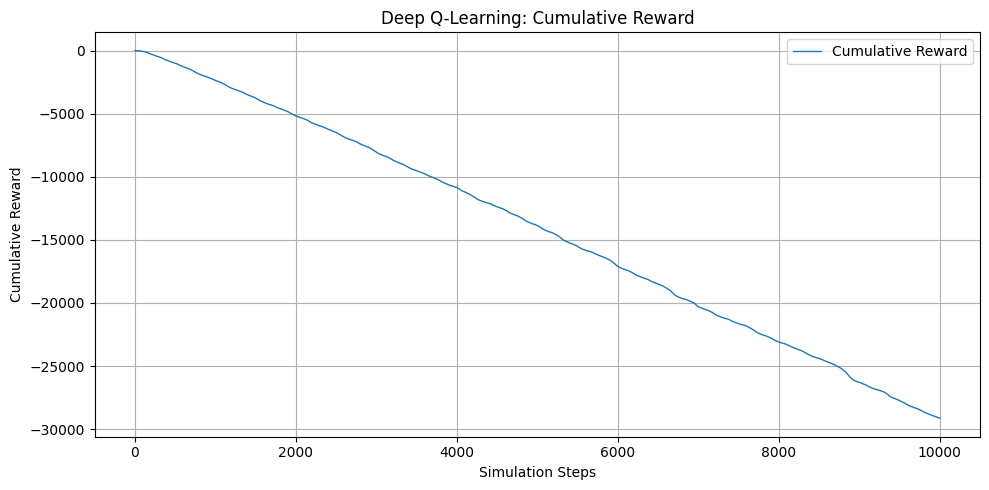

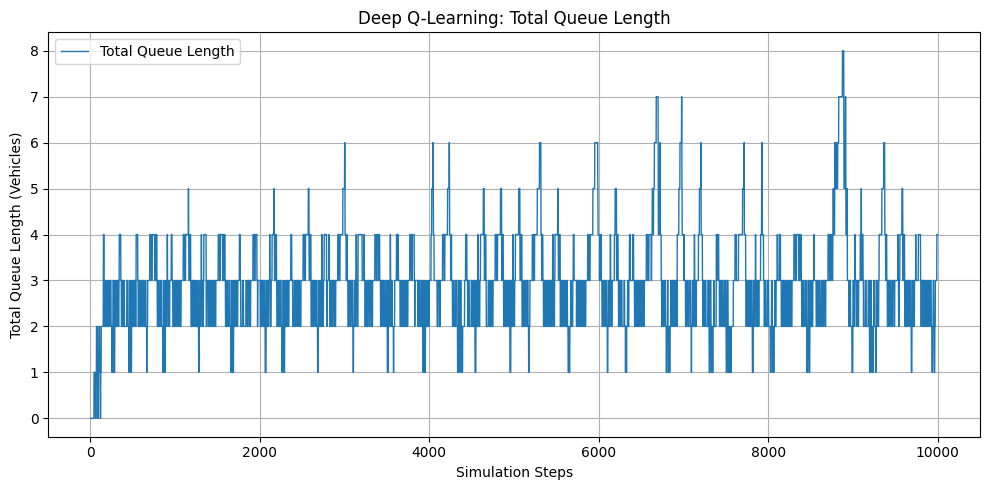


DEEP Q-LEARNING TRAINING COMPLETED
CSV file: DQN_results.csv
Graphs saved:
- DQN_cumulative_reward.png
- DQN_queue_length.png


In [2]:
%matplotlib inline

# ============================================================
# DEEP Q-LEARNING TRAFFIC SIGNAL CONTROL WITH SUMO & TRACI
# ============================================================

# ------------------------------------------------------------
# STEP 1: IMPORT LIBRARIES
# ------------------------------------------------------------

import os
import sys
import random
import csv
from collections import deque

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim


# ------------------------------------------------------------
# STEP 2: SET UP SUMO ENVIRONMENT
# ------------------------------------------------------------

if "SUMO_HOME" in os.environ:

    tools = os.path.join(os.environ["SUMO_HOME"], "tools")

    if tools not in sys.path:
        sys.path.append(tools)

else:
    sys.exit("Error: SUMO_HOME environment variable is not defined.")

import traci


# ------------------------------------------------------------
# STEP 3: SUMO CONFIGURATION
# ------------------------------------------------------------

# Run without GUI for faster training
SUMO_BINARY = "sumo"

SUMO_CONFIG = "RL.sumocfg"

sumo_cmd = [
    SUMO_BINARY,
    "-c", SUMO_CONFIG,
    "--step-length", "0.10",
    "--lateral-resolution", "0",
    "--no-step-log", "true",
    "--duration-log.disable"
]


# ------------------------------------------------------------
# STEP 4: DEFINE DETECTORS
# ------------------------------------------------------------

# Eastbound
EB_DETECTORS = [
    "Node1-2-EB-0",
    "Node1-2-EB-1",
    "Node1-2-EB-2"
]

# Southbound
SB_DETECTORS = [
    "Node1-2-SB-0",
    "Node1-2-SB-1",
    "Node1-2-SB-2"
]

# Combine all detectors
DETECTORS = EB_DETECTORS + SB_DETECTORS


# ------------------------------------------------------------
# STEP 5: TRAFFIC LIGHT ID
# ------------------------------------------------------------

TLS_ID = "Node2"


# ------------------------------------------------------------
# STEP 6: DQN PARAMETERS
# ------------------------------------------------------------

TOTAL_STEPS = 10000

GAMMA = 0.9

LEARNING_RATE = 0.001

EPSILON = 1.0
EPSILON_MIN = 0.05
EPSILON_DECAY = 0.9995

# Action 0 = Keep current phase
# Action 1 = Switch to next phase

ACTIONS = [0, 1]

# Minimum green time
MIN_GREEN_STEPS = 100

# 100 steps x 0.10 seconds = 10 seconds
last_switch_step = -MIN_GREEN_STEPS

BATCH_SIZE = 64

MEMORY_SIZE = 50000

TARGET_UPDATE_INTERVAL = 500

TRAINING_START = 500

TRAINING_INTERVAL = 4

PRINT_INTERVAL = 500


# ------------------------------------------------------------
# STEP 7: SET UP PYTORCH
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("DQN device:", device)


# ------------------------------------------------------------
# STEP 8: DEFINE DEEP Q-NETWORK
# ------------------------------------------------------------

# Input:
# 6 detector queue lengths + traffic light phase = 7 values
#
# Output:
# 2 Q-values
# Action 0 = Keep current phase
# Action 1 = Switch phase

STATE_SIZE = 7
ACTION_SIZE = 2


class DQN(nn.Module):

    def __init__(self):

        super(DQN, self).__init__()

        self.network = nn.Sequential(

            nn.Linear(STATE_SIZE, 128),
            nn.ReLU(),

            nn.Linear(128, 128),
            nn.ReLU(),

            nn.Linear(128, ACTION_SIZE)
        )

    def forward(self, state):

        return self.network(state)


# Main neural network
policy_net = DQN().to(device)

# Target neural network
target_net = DQN().to(device)

target_net.load_state_dict(policy_net.state_dict())

target_net.eval()


# Optimizer
optimizer = optim.Adam(
    policy_net.parameters(),
    lr=LEARNING_RATE
)

# Loss function
loss_function = nn.MSELoss()


# ------------------------------------------------------------
# STEP 9: EXPERIENCE REPLAY MEMORY
# ------------------------------------------------------------

memory = deque(maxlen=MEMORY_SIZE)


def store_experience(
    state,
    action,
    reward,
    next_state,
    done
):

    memory.append(
        (
            state,
            action,
            reward,
            next_state,
            done
        )
    )


# ------------------------------------------------------------
# STEP 10: GET CURRENT STATE
# ------------------------------------------------------------

def get_state():

    queue_lengths = [
        traci.lanearea.getLastStepVehicleNumber(detector_id)
        for detector_id in DETECTORS
    ]

    current_phase = traci.trafficlight.getPhase(TLS_ID)

    # Normalize queue lengths
    normalized_queues = [
        queue / 50.0
        for queue in queue_lengths
    ]

    # Normalize traffic-light phase
    program_logics = traci.trafficlight.getAllProgramLogics(TLS_ID)

    num_phases = len(program_logics[0].phases)

    if num_phases > 1:

        normalized_phase = current_phase / (num_phases - 1)

    else:

        normalized_phase = 0.0

    state = np.array(
        normalized_queues + [normalized_phase],
        dtype=np.float32
    )

    return state


# ------------------------------------------------------------
# STEP 11: REWARD FUNCTION
# ------------------------------------------------------------

def get_reward(state):

    # State contains 6 normalized detector queues + phase
    # Convert normalized queues back to approximate queue counts

    total_queue = sum(state[:-1]) * 50.0

    # Negative total queue length
    reward = -total_queue

    return reward


# ------------------------------------------------------------
# STEP 12: ACTION SELECTION
# ------------------------------------------------------------

def choose_action(state, current_step):

    # Enforce minimum green time
    if current_step - last_switch_step < MIN_GREEN_STEPS:

        return 0

    # Epsilon-greedy exploration
    if random.random() < EPSILON:

        return random.choice(ACTIONS)

    else:

        state_tensor = torch.FloatTensor(
            state
        ).unsqueeze(0).to(device)

        with torch.no_grad():

            q_values = policy_net(state_tensor)

        action = torch.argmax(q_values).item()

        return action


# ------------------------------------------------------------
# STEP 13: APPLY ACTION
# ------------------------------------------------------------

def apply_action(action, current_step):

    global last_switch_step

    # Action 0: Keep current phase
    if action == 0:

        return

    # Action 1: Switch phase
    if action == 1:

        # Check minimum green time
        if current_step - last_switch_step >= MIN_GREEN_STEPS:

            program_logics = traci.trafficlight.getAllProgramLogics(TLS_ID)

            num_phases = len(program_logics[0].phases)

            current_phase = traci.trafficlight.getPhase(TLS_ID)

            next_phase = (current_phase + 1) % num_phases

            traci.trafficlight.setPhase(TLS_ID, next_phase)

            last_switch_step = current_step


# ------------------------------------------------------------
# STEP 14: TRAIN THE DQN
# ------------------------------------------------------------

def train_dqn():

    if len(memory) < BATCH_SIZE:

        return None

    # Randomly sample experiences
    batch = random.sample(memory, BATCH_SIZE)

    states = torch.FloatTensor(
        np.array([experience[0] for experience in batch])
    ).to(device)

    actions = torch.LongTensor(
        [experience[1] for experience in batch]
    ).unsqueeze(1).to(device)

    rewards = torch.FloatTensor(
        [experience[2] for experience in batch]
    ).to(device)

    next_states = torch.FloatTensor(
        np.array([experience[3] for experience in batch])
    ).to(device)

    dones = torch.FloatTensor(
        [experience[4] for experience in batch]
    ).to(device)


    # Current Q-values
    current_q_values = policy_net(states).gather(
        1, actions
    ).squeeze(1)


    # Target Q-values
    with torch.no_grad():

        next_q_values = target_net(next_states).max(1)[0]

        target_q_values = rewards + (
            GAMMA * next_q_values * (1 - dones)
        )


    # Calculate loss
    loss = loss_function(
        current_q_values,
        target_q_values
    )


    # Update neural network
    optimizer.zero_grad()

    loss.backward()

    # Prevent excessively large gradients
    torch.nn.utils.clip_grad_norm_(
        policy_net.parameters(),
        max_norm=1.0
    )

    optimizer.step()

    return loss.item()


# ------------------------------------------------------------
# STEP 15: INITIALIZE PERFORMANCE METRICS
# ------------------------------------------------------------

cumulative_reward = 0

cumulative_rewards = []
queue_history = []
reward_history = []

phase_history = []
action_history = []

loss_history = []

simulation_completed = False


# ------------------------------------------------------------
# STEP 16: START SUMO
# ------------------------------------------------------------

print("\nStarting SUMO simulation...")

traci.start(sumo_cmd)

print("SUMO started successfully.")

# Reset minimum green counter
last_switch_step = -MIN_GREEN_STEPS


# ------------------------------------------------------------
# STEP 17: RUN DEEP Q-LEARNING
# ------------------------------------------------------------

try:

    for step in range(TOTAL_STEPS):

        # Get current state
        state = get_state()


        # Select action
        action = choose_action(state, step)


        # Apply traffic signal action
        apply_action(action, step)


        # Advance SUMO simulation
        traci.simulationStep()


        # Get next state
        next_state = get_state()


        # Calculate reward
        reward = get_reward(next_state)


        # Update cumulative reward
        cumulative_reward += reward


        # Store experience
        store_experience(
            state,
            action,
            reward,
            next_state,
            False
        )


        # Train neural network
        loss = None

        if step >= TRAINING_START:

            if step % TRAINING_INTERVAL == 0:

                loss = train_dqn()

                if loss is not None:

                    loss_history.append(loss)


        # Update target network periodically
        if (step + 1) % TARGET_UPDATE_INTERVAL == 0:

            target_net.load_state_dict(
                policy_net.state_dict()
            )


        # Decay exploration rate
        if step >= TRAINING_START:

            EPSILON = max(
                EPSILON_MIN,
                EPSILON * EPSILON_DECAY
            )


        # Record total queue length
        total_queue = sum(
            traci.lanearea.getLastStepVehicleNumber(detector_id)
            for detector_id in DETECTORS
        )


        # Store performance metrics
        cumulative_rewards.append(cumulative_reward)

        queue_history.append(total_queue)

        reward_history.append(reward)

        phase_history.append(
            traci.trafficlight.getPhase(TLS_ID)
        )

        action_history.append(action)


        # Print progress periodically
        if (step + 1) % PRINT_INTERVAL == 0:

            average_queue = np.mean(
                queue_history[-PRINT_INTERVAL:]
            )

            average_reward = np.mean(
                reward_history[-PRINT_INTERVAL:]
            )

            # Average recent training loss
            loss_window = max(
                1,
                PRINT_INTERVAL // TRAINING_INTERVAL
            )

            average_loss = (
                np.mean(loss_history[-loss_window:])
                if loss_history else 0.0
            )

            print(
                f"Step: {step + 1:5d}/{TOTAL_STEPS} | "
                f"Phase: {traci.trafficlight.getPhase(TLS_ID)} | "
                f"Action: {action} | "
                f"Queue: {total_queue:3d} | "
                f"Avg Queue: {average_queue:.2f} | "
                f"Avg Reward: {average_reward:.2f} | "
                f"Loss: {average_loss:.4f} | "
                f"Epsilon: {EPSILON:.3f} | "
                f"Memory: {len(memory)}"
            )

    simulation_completed = True


finally:

    # Always close SUMO
    if traci.isLoaded():

        traci.close()

    print("\nSUMO simulation finished.")


# ------------------------------------------------------------
# STEP 18: DISPLAY FINAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 50)
print("DEEP Q-LEARNING SIMULATION RESULTS")
print("=" * 50)

print("Training completed:", simulation_completed)

print("Total simulation steps:", len(cumulative_rewards))

print(
    "Total simulated time:",
    len(cumulative_rewards) * 0.10,
    "seconds"
)

print("Experience memory size:", len(memory))

print("Final epsilon:", round(EPSILON, 4))

print("Final cumulative reward:", cumulative_reward)

if queue_history:

    print(
        "Average queue length:",
        round(np.mean(queue_history), 2)
    )

    print(
        "Maximum queue length:",
        max(queue_history)
    )

    print(
        "Minimum queue length:",
        min(queue_history)
    )

    print(
        "Final queue length:",
        queue_history[-1]
    )


# ------------------------------------------------------------
# STEP 19: SAVE RESULTS TO CSV
# ------------------------------------------------------------

output_file = "DQN_results.csv"

with open(output_file, "w", newline="") as file:

    writer = csv.writer(file)

    writer.writerow([
        "Step",
        "Action",
        "Phase",
        "Queue_Length",
        "Reward",
        "Cumulative_Reward"
    ])

    for i in range(len(queue_history)):

        writer.writerow([
            i + 1,
            action_history[i],
            phase_history[i],
            queue_history[i],
            reward_history[i],
            cumulative_rewards[i]
        ])

print(f"\nResults saved to: {output_file}")


# ------------------------------------------------------------
# STEP 20: PLOT CUMULATIVE REWARD
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_rewards) + 1),
    cumulative_rewards,
    linewidth=1,
    label="Cumulative Reward"
)

plt.xlabel("Simulation Steps")
plt.ylabel("Cumulative Reward")
plt.title("Deep Q-Learning: Cumulative Reward")

plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    "DQN_cumulative_reward.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# STEP 21: PLOT TOTAL QUEUE LENGTH
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(queue_history) + 1),
    queue_history,
    linewidth=1,
    label="Total Queue Length"
)

plt.xlabel("Simulation Steps")
plt.ylabel("Total Queue Length (Vehicles)")
plt.title("Deep Q-Learning: Total Queue Length")

plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    "DQN_queue_length.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# STEP 22: FINAL MESSAGE
# ------------------------------------------------------------

print("\n" + "=" * 50)
print("DEEP Q-LEARNING TRAINING COMPLETED")
print("=" * 50)

print("CSV file:", output_file)

print("Graphs saved:")
print("- DQN_cumulative_reward.png")
print("- DQN_queue_length.png")